# 04 · Banco de imagens com GridFS

**Pré-requisito:** notebooks 00 a 03.

**Nesta etapa:** guardar arquivos (imagens) no MongoDB e consultá-los pelos metadados.

As seções 4 a 7 são um **passo a passo**: todas as células já estão preenchidas. Rode uma por vez e observe o resultado. No final ficam os **Exercícios 5, 6 e 7**, para você fazer seguindo os exemplos.

> **Sobre os dados:** o *FEI Face Database* (Centro Universitário FEI, São Bernardo do Campo) é liberado **apenas para fins de pesquisa**, com permissão de uso, mas **não de redistribuição ou reprodução**. Use as imagens só nesta atividade e não as publique abertamente.

In [22]:
%pip install -q pymongo python-dotenv pillow numpy matplotlib requests

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## Conexão com o seu MongoDB

A célula abaixo lê o endereço do banco (`MONGO_URI`) do arquivo **`.env`** da pasta, criado no notebook 00, e testa a conexão. Se der erro, confira se o MongoDB está rodando (notebook 00, Etapa 4).

In [23]:
import os
from dotenv import load_dotenv
from pymongo import MongoClient

load_dotenv()                                   # lê o arquivo .env da pasta
client = MongoClient(os.environ["MONGO_URI"])
client.admin.command("ping")
print("Conectado ao MongoDB")

Conectado ao MongoDB


---
## 1. Por que não guardar a imagem dentro de um documento comum?

- Um documento BSON tem limite de **16 MB**. Fotos grandes, vídeos e PDFs podem passar disso.
- Mesmo abaixo do limite, ler um documento enorme só para saber o nome do arquivo é desperdício.

## 2. GridFS: a mudança em caixas numeradas

O guarda-roupa não passa pela porta: é desmontado, cada peça vai numa caixa numerada, e uma **etiqueta-mestre** diz o que é e como remontar.

| Coleção | Conteúdo | Na analogia |
|---|---|---|
| `fs.files` | um documento por arquivo: `filename`, `length`, `uploadDate`, **`metadata`** | a etiqueta-mestre |
| `fs.chunks` | os pedaços do arquivo (até 255 KB cada), numerados `n = 0, 1, 2…` | as caixas |

`fs.files` é uma coleção **comum**: dá para filtrar, agregar e paginar pelos metadados com tudo o que você aprendeu no notebook 02.

| Comando | O que faz |
|---|---|
| `fs = gridfs.GridFS(db)` | abre o GridFS no banco |
| `fs.put(bytes, filename=..., metadata={...})` | grava e devolve o `_id` |
| `fs.get(id).read()` | lê os bytes |
| `fs.find_one({...})` / `fs.find({...})` | busca um / vários arquivos |
| `fs.exists(filename=...)` | verifica se já existe |
| `fs.delete(id)` | apaga o arquivo e todos os seus chunks |

---
## 3. Baixar o banco de faces

Vamos usar a pasta **frontalimages_manuallyaligned_part1** (cerca de 6 MB): fotos frontais, duas por pessoa.

**Convenção de nomes:** `12a.jpg` = pessoa 12, expressão **neutra** · `12b.jpg` = pessoa 12, **sorrindo**.

A célula abaixo tenta baixar e descompactar automaticamente na pasta `faces`. Se o download falhar, baixe manualmente pela página **https://fei.edu.br/~cet/facedatabase.html** (link *frontalimages_manuallyaligned_part1*), coloque o `.zip` na pasta da disciplina (a mesma deste notebook) e rode a célula de novo.

In [24]:
import os, zipfile, glob, requests

ZIP = "frontalimages_manuallyaligned_part1.zip"
URL = "https://fei.edu.br/~cet/" + ZIP

if not os.path.exists(ZIP):
    try:
        r = requests.get(URL, timeout=60)
        r.raise_for_status()
        open(ZIP, "wb").write(r.content)
        print("Download concluído")
    except Exception as e:
        print("Não consegui baixar automaticamente:", e)
        print("Baixe manualmente em https://fei.edu.br/~cet/facedatabase.html e envie o .zip para esta pasta.")

if os.path.exists(ZIP):
    with zipfile.ZipFile(ZIP) as z:
        z.extractall("faces")

# as imagens podem estar dentro de uma subpasta: procuramos em qualquer nível
imagens = sorted(glob.glob("faces/**/*.jpg", recursive=True))
PASTA = os.path.dirname(imagens[0]) if imagens else "faces"
print(len(imagens), "imagens em", PASTA)

200 imagens em faces


100a.jpg (260, 360) 32.2 KB


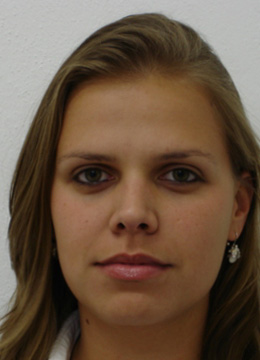

In [25]:
from PIL import Image
from IPython.display import display

if imagens:
    exemplo = Image.open(imagens[0])
    print(os.path.basename(imagens[0]), exemplo.size, f"{os.path.getsize(imagens[0]) / 1024:.1f} KB")
    display(exemplo)

---
## 4. Abrir o GridFS e gravar a primeira imagem

O GridFS fica dentro de um banco comum. Vamos usar o banco **`faces_db`**: ele, o `fs.files` e o `fs.chunks` nascem sozinhos na primeira gravação.

A célula abaixo:
- abre a conexão de novo, por segurança (funciona mesmo que o kernel tenha sido reiniciado);
- **apaga o banco `faces_db` inteiro** com `drop_database`, para começar do zero. Assim você pode rodar o notebook quantas vezes quiser sem acumular imagens repetidas.

In [26]:
import os, io, gridfs
from dotenv import load_dotenv
from pymongo import MongoClient

load_dotenv()
client = MongoClient(os.environ["MONGO_URI"])

client.drop_database("faces_db")      # começa do zero: apaga fs.files e fs.chunks antigos
print("Bancos agora:", client.list_database_names())

db = client["faces_db"]
fs = gridfs.GridFS(db)

Bancos agora: ['admin', 'aula', 'config', 'escola', 'local']


Para gravar, lemos o arquivo **em bytes** (`"rb"` = *read binary*) e entregamos ao `fs.put`. Junto vão o nome (`filename`) e os **metadados**: um dicionário livre, que depois serve para buscar.

In [27]:
caminho = os.path.join(PASTA, "1a.jpg")
with open(caminho, "rb") as f:
    dados = f.read()

file_id = fs.put(dados, filename="1a.jpg", metadata={"pessoa": 1, "expressao": "neutra"})
print("Gravado com _id:", file_id)

Gravado com _id: 6b0376a6a7f4de50bbd8080c


### O que foi parar em cada coleção?

A etiqueta (`fs.files`) e as caixas (`fs.chunks`) estão ligadas pelo campo `files_id`.

In [28]:
etiqueta = db.fs.files.find_one({"_id": file_id})
print(etiqueta)

n_chunks = db.fs.chunks.count_documents({"files_id": file_id})
print(f"\n{etiqueta['length'] / 1024:.1f} KB divididos em {n_chunks} chunk(s)")

{'_id': ObjectId('6b0376a6a7f4de50bbd8080c'), 'filename': '1a.jpg', 'metadata': {'pessoa': 1, 'expressao': 'neutra'}, 'chunkSize': 261120, 'length': 32308, 'uploadDate': datetime.datetime(2026, 11, 22, 23, 11, 34, 319000)}

31.6 KB divididos em 1 chunk(s)


**Só 1 chunk.** As fotos da FEI têm poucas dezenas de KB, menos que os 255 KB de um chunk, então cabem numa caixa só. Um vídeo de 10 MB geraria cerca de 40 chunks.

### Ler a imagem de volta

`fs.find_one` busca pela etiqueta e devolve o arquivo; `.read()` remonta os bytes a partir dos chunks. O `io.BytesIO` faz os bytes parecerem um arquivo, para o `Image.open` conseguir abrir.

1a.jpg {'pessoa': 1, 'expressao': 'neutra'}


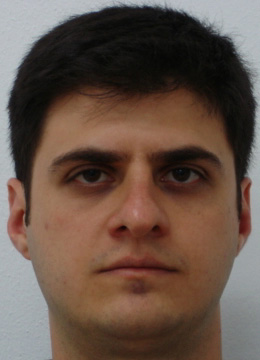

In [29]:
arquivo = fs.find_one({"filename": "1a.jpg"})
print(arquivo.filename, arquivo.metadata)

display(Image.open(io.BytesIO(arquivo.read())))

---
## 5. Gravar o banco de faces inteiro

Agora todas as imagens. Três cuidados:

- **Sem duplicatas:** `fs.exists(filename=...)` verifica se o arquivo já está no banco; se estiver, pulamos. Assim a célula pode ser rodada várias vezes sem repetir nada (a `1a.jpg` já está lá e será pulada).
- **Metadados a partir do nome:** em `"12b.jpg"`, a parte antes do ponto é `"12b"`: o número (`"12"`) é a pessoa e a última letra (`"b"`) é a expressão.
- **Tamanho da imagem:** `Image.open(...).size` devolve largura e altura.

In [30]:
gravadas = 0
puladas = 0

for caminho in imagens:
    nome = os.path.basename(caminho)          # "12b.jpg"
    if fs.exists(filename=nome):
        puladas += 1
        continue

    with open(caminho, "rb") as f:
        dados = f.read()
    largura, altura = Image.open(io.BytesIO(dados)).size

    base = nome.split(".")[0]                 # "12b"
    pessoa = int(base[:-1])                   # 12
    expressao = "neutra" if base[-1].lower() == "a" else "sorrindo"

    fs.put(dados, filename=nome, metadata={
        "pessoa": pessoa,
        "expressao": expressao,
        "largura": largura,
        "altura": altura,
        "origem": "FEI",
    })
    gravadas += 1

print(f"Gravadas: {gravadas} | puladas: {puladas} | total no banco: {db.fs.files.count_documents({})}")

Gravadas: 199 | puladas: 1 | total no banco: 200


Rode a célula acima **mais uma vez**: agora todas são puladas e o total não muda. A célula abaixo confere o banco:

In [31]:
total_banco = db.fs.files.count_documents({})
duplicados = list(db.fs.files.aggregate([
    {"$group": {"_id": "$filename", "n": {"$sum": 1}}},
    {"$match": {"n": {"$gt": 1}}},
]))
sem_metadados = db.fs.files.count_documents({"metadata.pessoa": {"$exists": False}})

print("Todas as imagens no banco:", "OK" if total_banco == len(imagens) else f"FALTA ({total_banco} de {len(imagens)})")
print("Nenhum arquivo duplicado: ", "OK" if not duplicados else f"FALTA {[d['_id'] for d in duplicados][:5]}")
print("Todos com metadados:      ", "OK" if sem_metadados == 0 else f"FALTA ({sem_metadados} sem metadata.pessoa)")

Todas as imagens no banco: OK
Nenhum arquivo duplicado:  OK
Todos com metadados:       OK


---
## 6. Consultando as imagens pelos metadados

`fs.files` é uma coleção comum: valem `find`, `count_documents` e `aggregate` do notebook 02. Os metadados ficam dentro do campo `metadata`, então o caminho é `metadata.pessoa`, `metadata.expressao`…

**Quantas imagens de cada expressão?**

In [32]:
for r in db.fs.files.aggregate([
    {"$group": {"_id": "$metadata.expressao", "total": {"$sum": 1}}},
]):
    print(r)

{'_id': 'sorrindo', 'total': 100}
{'_id': 'neutra', 'total': 100}


**Qual o tamanho médio dos arquivos?** O `length` de cada etiqueta está em bytes; dividimos por 1024 para ter KB.

In [33]:
r = list(db.fs.files.aggregate([
    {"$group": {"_id": None, "media": {"$avg": "$length"}}},
]))[0]
print(f"Tamanho médio: {r['media'] / 1024:.1f} KB")

Tamanho médio: 31.4 KB


**Galeria:** pessoas 1 a 5, foto neutra e sorrindo lado a lado. Para cada pessoa e expressão, `fs.find_one` busca pelos metadados, e o `matplotlib` desenha a imagem numa grade 5 × 2.

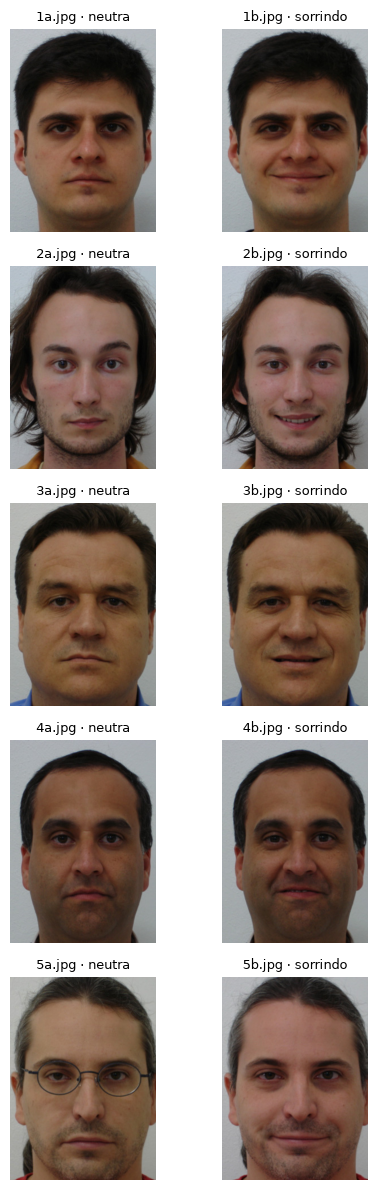

In [34]:
import matplotlib.pyplot as plt

fig, eixos = plt.subplots(5, 2, figsize=(5, 12))
for linha, pessoa in enumerate(range(1, 6)):
    for coluna, expressao in enumerate(["neutra", "sorrindo"]):
        ax = eixos[linha][coluna]
        ax.axis("off")
        arq = fs.find_one({"metadata.pessoa": pessoa, "metadata.expressao": expressao})
        if arq:
            ax.imshow(Image.open(io.BytesIO(arq.read())), cmap="gray")
            ax.set_title(f"{arq.filename} · {expressao}", fontsize=9)
plt.tight_layout()
plt.show()

---
## 7. Apagando arquivos

`fs.delete(id)` apaga a etiqueta **e** todos os chunks daquele arquivo. Para apagar pelas informações dos metadados, buscamos com `fs.find` e apagamos um a um. Vamos apagar as fotos da pessoa 5:

In [35]:
antes = db.fs.files.count_documents({})
for arq in fs.find({"metadata.pessoa": 5}):
    print("Apagando", arq.filename)
    fs.delete(arq._id)

print("Antes:", antes, "| depois:", db.fs.files.count_documents({}))
print("Chunks sem etiqueta (deve ser 0):", db.fs.chunks.count_documents({"files_id": {"$nin": db.fs.files.distinct("_id")}}))

Apagando 5a.jpg
Apagando 5b.jpg
Antes: 200 | depois: 198
Chunks sem etiqueta (deve ser 0): 0


Nenhum chunk ficou para trás. Para o próximo notebook precisamos do banco completo, então vamos devolver as fotos da pessoa 5, com os mesmos metadados da seção 5:

In [36]:
for nome in ["5a.jpg", "5b.jpg"]:
    with open(os.path.join(PASTA, nome), "rb") as f:
        dados = f.read()
    largura, altura = Image.open(io.BytesIO(dados)).size
    expressao = "neutra" if nome[-5] == "a" else "sorrindo"
    fs.put(dados, filename=nome, metadata={
        "pessoa": 5, "expressao": expressao,
        "largura": largura, "altura": altura, "origem": "FEI",
    })

print("Total no banco:", db.fs.files.count_documents({}), "de", len(imagens))

Total no banco: 200 de 200


---
## Agora é a sua vez · Exercícios 5, 6 e 7

Use os exemplos acima como modelo.

### Exercício 5 · Busca pelos metadados
Mostre o `filename` de todas as fotos **sorrindo** das pessoas **10 a 15**, ordenadas pelo número da pessoa.

*Você vai usar:* `db.fs.files.find` com `$gte`/`$lte` em `metadata.pessoa`, e `.sort`.

In [37]:
# Exercício 5
# seu código aqui

### Exercício 6 · A maior e a menor imagem
Mostre o `filename` e o tamanho em KB da **maior** e da **menor** imagem do banco.

*Você vai usar:* `db.fs.files.find` ordenado por `length` (`-1` para a maior, `1` para a menor) com `.limit(1)`, ou `find_one` com `sort`.

In [38]:
# Exercício 6
# seu código aqui

### Exercício 7 · Uma imagem sua
1. Coloque uma foto `.jpg` qualquer na pasta deste notebook (se não tiver, copie uma das faces e dê outro nome, por exemplo `minha_foto.jpg`).
2. Grave-a no GridFS com os metadados `pessoa: 999`, `expressao: "neutra"` e `origem: "aluno"`.
3. Busque-a de volta **pelos metadados** e exiba-a.
4. Apague-a e mostre que o total do banco voltou ao que era antes.

In [39]:
# 7.1 Gravar a sua imagem
# seu código aqui

In [40]:
# 7.2 Buscar pelos metadados e exibir
# seu código aqui

In [41]:
# 7.3 Apagar e conferir o total
# seu código aqui

**Próximo:** `05_App_Galeria_e_Desafio.ipynb`